# Deep Neural Network
## Assignment A05

## Tensor Flow
- Select number of layers
- Select node in each of the layers
- Choose activation function
- multi-class - Fashion MNIST dataset (all 60000 images)
- Implement one or more of following to achieve max accuracy.
    - L1/ L2 Regularization
    - Dropout
    - Batch Normalization
    - Early stopping
- Save model

Your Name and PRN:
- Name: Anand Haresh Karmarkar
- PRN : 8012

In [28]:
###-----------------
### Import libraries
###-----------------
from pathlib import Path  # Import Path for file system path operations and management
import numpy as np  # Import NumPy for numerical computations and array operations
import pandas as pd  # Import Pandas for data manipulation and analysis with DataFrames
import matplotlib.pyplot as plt  # Import Matplotlib for creating static, interactive visualizations
import seaborn as sns  # Import Seaborn for statistical data visualization built on Matplotlib

from sklearn.model_selection import train_test_split  # Import function to split dataset into training and testing subsets
from sklearn.metrics import accuracy_score, classification_report  # Import function to calculate various metric
import tensorflow as tf

In [29]:
import tensorflow as tf

# Check if a GPU is available and configure GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
        print(f"GPU is available: {gpus}")
        print(f"Active GPU Device: {tf.test.gpu_device_name()}")
    except RuntimeError as e:
        print(e)
else:
    print("No GPU detected. Please change your Colab runtime type to GPU (Runtime -> Change runtime type -> GPU).")

GPU is available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Active GPU Device: /device:GPU:0


In [30]:
RANDOM_STATE = 24 # for initialization ----- REMEMBER: to remove at the time of promotion to production
np.random.seed(RANDOM_STATE)
rng = np.random.default_rng(seed = RANDOM_STATE) # Set Random Seed for reproducible  results

EPOCHS = 25 # number of epochs
BATCH_SIZE = 32
ALPHA = 0.001 # learning rate
TEST_SIZE = 0.2
ALPHA = 0.001 # learning rate
WEIGHT_DECAY = 1e-4

TRAIN_SIZE = int(BATCH_SIZE*18) # to create 64 batches of 256 rows each
PATIENCE = 20
LR_PATIENCE = 5
LR_FACTOR= 0.1

# parameters for Matplotlib
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (15, 6),
          'axes.labelsize': 'x-large',
          'axes.titlesize':'x-large',
          'xtick.labelsize':'x-large',
          'ytick.labelsize':'x-large'
         }

plt.rcParams.update(params)

CMAP = plt.cm.coolwarm
plt.style.use('seaborn-v0_8-darkgrid') # plt.style.use('ggplot')

In [31]:
train_df = pd.read_csv('/content/fashion-mnist_train.csv')
test_df = pd.read_csv('/content/fashion-mnist_test.csv')

In [32]:
class_names = {0: 'T-shirt/top',1:'Trouser',2:'Pullover',3:'Dress',4:'Coat',
               5:'Sandal', 6: 'Shirt',7: 'Sneaker', 8:'Bag', 9: 'Ankle boot'}

In [33]:
train_df.head()

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [34]:
train_df.shape, test_df.shape

((60000, 785), (10000, 785))

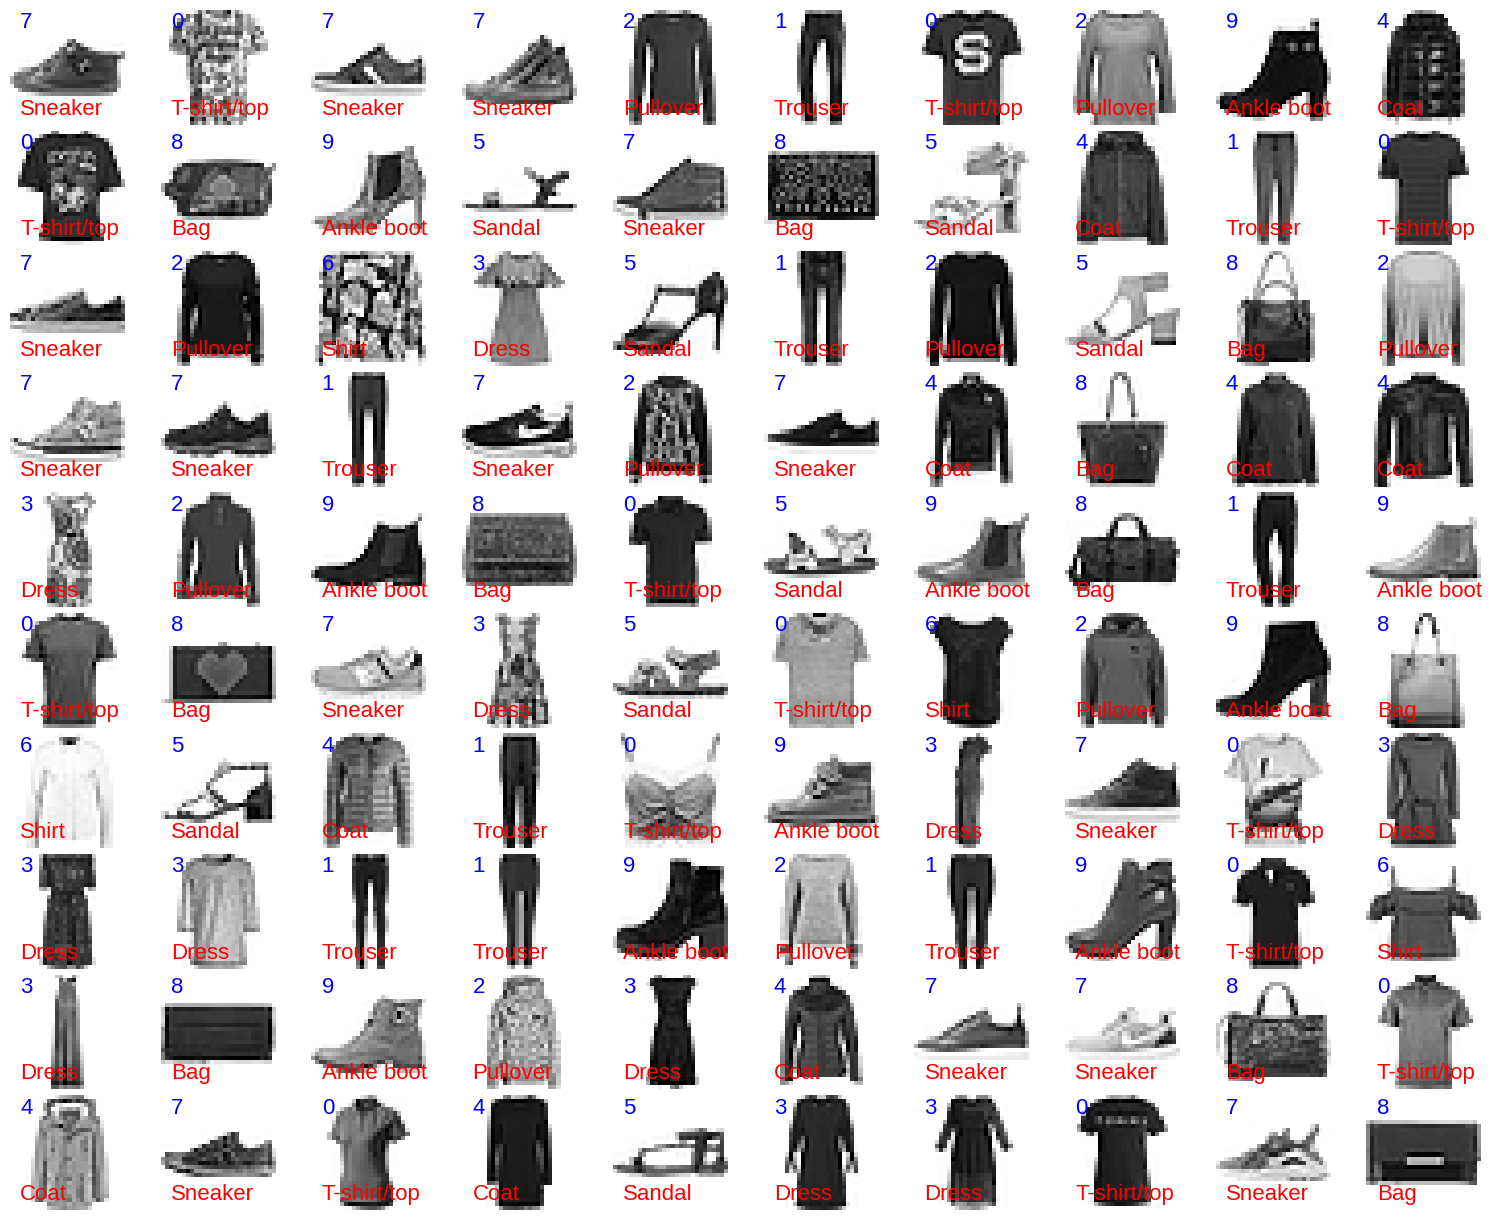

In [35]:
# Sample data plot

plot_df = train_df.sample(n = 100) # Take 100 sample from the training set

fig = plt.figure(figsize=(15, 12))  # figure size in inches

fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.05, wspace=0.05) # adjust subplots

i = 0

for _ , row in plot_df.iterrows(): # iterate through all rows of the dataframe

    i = i + 1

    image = row.values[1:].reshape(28,28) # reshape row to a 28x28 matrix

    ax = fig.add_subplot(10, 10, (i), xticks=[], yticks=[]) # add a subplot to the figure

    ax.imshow(image, cmap=plt.cm.binary, interpolation='nearest') # show image on the axis

    ax.text(2, 4, str(row.iloc[0]), color='b', fontsize=16)   # add number (class) of the image

    ax.text(2, 25, class_names[row.iloc[0]], color='r', fontsize=16)   # add name of the image

plt.show()

In [36]:
X_train = train_df.drop('label', axis = 1).to_numpy()
y_train = train_df['label'].to_numpy()

X_test = test_df.drop('label', axis = 1).to_numpy()
y_test = test_df['label'].to_numpy()

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((60000, 784), (10000, 784), (60000,), (10000,))

In [37]:
# Clean NaNs from the datasets before splitting
train_df_clean = train_df.dropna()
test_df_clean = test_df.dropna()

print(f"Original training shape: {train_df.shape}, Cleaned shape: {train_df_clean.shape}")
print(f"Original testing shape: {test_df.shape}, Cleaned shape: {test_df_clean.shape}")

X_train = train_df_clean.drop('label', axis=1).to_numpy()
y_train = train_df_clean['label'].to_numpy().astype(int)

X_test = test_df_clean.drop('label', axis=1).to_numpy()
y_test = test_df_clean['label'].to_numpy().astype(int)


Original training shape: (60000, 785), Cleaned shape: (60000, 785)
Original testing shape: (10000, 785), Cleaned shape: (10000, 785)


In [38]:
# Re-apply normalization
X_train = X_train / 255.0
X_test = X_test / 255.0


In [39]:
# Re-create TensorFlow datasets
train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.cache()
train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size=tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.cache()
test_ds = test_ds.shuffle(buffer_size=X_test.shape[0]).batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size=tf.data.AUTOTUNE)


In [40]:
X_train = X_train / 255.0

X_test = X_test / 255.0

In [41]:
class_names = list(class_names.values())
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

In [42]:
import tensorflow as tf

train_ds = tf.data.Dataset.from_tensor_slices((X_train, y_train))
train_ds = train_ds.cache()
train_ds = train_ds.shuffle(buffer_size=X_train.shape[0]).batch(BATCH_SIZE)
train_ds = train_ds.prefetch(buffer_size = tf.data.AUTOTUNE)

In [43]:
test_ds = tf.data.Dataset.from_tensor_slices((X_test, y_test))
test_ds = test_ds.cache()
test_ds = test_ds.shuffle(buffer_size=X_test.shape[0]).batch(BATCH_SIZE)
test_ds = test_ds.prefetch(buffer_size = tf.data.AUTOTUNE)

In [44]:
initializer = tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE)
optimizer = tf.keras.optimizers.Adam(learning_rate=ALPHA)

loss_fun = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)

model1 = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(784,)),
    tf.keras.layers.Dense(392, activation='relu', kernel_initializer=initializer),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(196, activation='relu', kernel_initializer=initializer),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(98, activation='relu', kernel_initializer=initializer),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(49, activation='relu', kernel_initializer=initializer),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(24, activation='relu', kernel_initializer=initializer),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(10)
])

In [45]:
model1.compile(
    optimizer=optimizer,
    loss=loss_fun,
    metrics=['accuracy']
)

In [46]:
history = model1.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds)

Epoch 1/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 11s 4ms/step - accuracy: 0.6004 - loss: 1.0200 - val_accuracy: 0.7635 - val_loss: 0.6438
Epoch 2/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7605 - loss: 0.6524 - val_accuracy: 0.7975 - val_loss: 0.5297
Epoch 3/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.7876 - loss: 0.5781 - val_accuracy: 0.8121 - val_loss: 0.4909
Epoch 4/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8029 - loss: 0.5378 - val_accuracy: 0.8265 - val_loss: 0.4442
Epoch 5/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8164 - loss: 0.5092 - val_accuracy: 0.8355 - val_loss: 0.4545
Epoch 6/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8242 - loss: 0.4893 - val_accuracy: 0.8424 - val_loss: 0.4344
Epoch 7/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8331 - loss: 0.4732 - val_accuracy: 0.8440 - val_loss: 0.4278
Epoch 8/25
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.8425 - loss: 0.4538 -

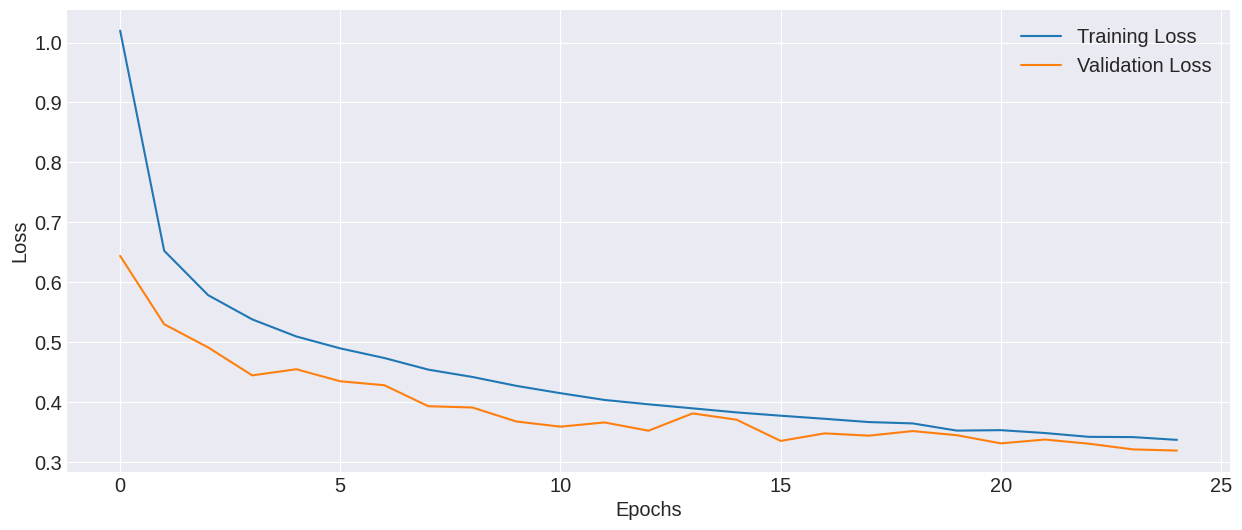

In [47]:
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

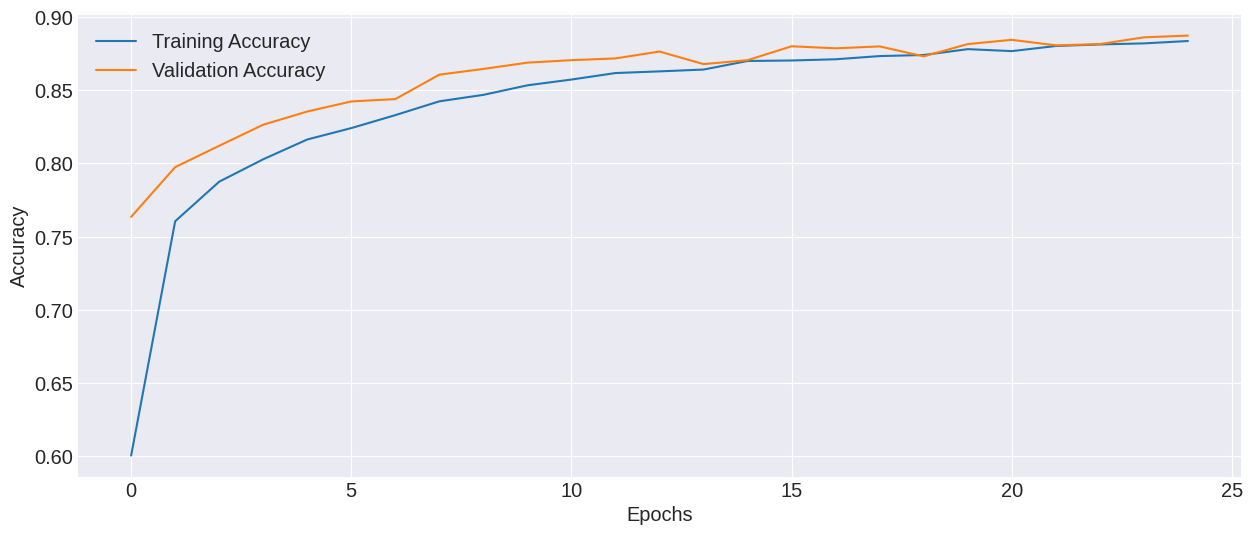

In [48]:
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

# Deep Neural Network
## Assignment A05

## Tensor Flow
- Select number of layers
- Select node in each of the layers
- Choose activation function
- multi-class - Fashion MNIST dataset (all 60000 images)
- Implement one or more of following to achieve max accuracy.
    - L1/ L2 Regularization
    - Dropout
    - Batch Normalization
    - Early stopping
- Save model

In [49]:
import tensorflow as tf

# Configure Explicit Model Layers
model2 = tf.keras.Sequential([
    # Input layer representing flattened image dimensions
    tf.keras.layers.Input(shape=(784,)),

    # Layer 1: Dense -> Batch Normalization -> Activation -> Dropout
    tf.keras.layers.Dense(392,
                          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE),
                          kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.2),

    # Layer 2: Dense -> Batch Normalization -> Activation -> Dropout
    tf.keras.layers.Dense(196,
                          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE),
                          kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.2),

    # Layer 3: Dense -> Batch Normalization -> Activation -> Dropout
    tf.keras.layers.Dense(98,
                          kernel_initializer=tf.keras.initializers.GlorotUniform(seed=RANDOM_STATE),
                          kernel_regularizer=tf.keras.regularizers.l2(WEIGHT_DECAY)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.Dropout(0.2),

    # Output Layer producing raw logits for 10 classes
    tf.keras.layers.Dense(10)
])

model2.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_12 (Dense)                │ (None, 392)            │       307,720 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 392)            │         1,568 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 392)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 392)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 196)            │        77,028 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 196)            │           784 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 196)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 196)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 98)             │        19,306 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 98)             │           392 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 98)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 98)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 10)             │           990 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 407,788 (1.56 MB)

 Trainable params: 406,416 (1.55 MB)

 Non-trainable params: 1,372 (5.36 KB)

In [50]:
# Compile Model
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=ALPHA),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Define Callback strategies
early_stop_callback = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=PATIENCE,
    restore_best_weights=True,
    verbose=1
)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath='best_model_explicit.keras',
    monitor='val_loss',
    save_best_only=True,
    verbose=1
)

In [51]:
# Train Model
history_explicit = model2.fit(
    train_ds,
    epochs=EPOCHS,
    validation_data=test_ds,
    callbacks=[early_stop_callback, checkpoint_callback]
)

Epoch 1/25
1868/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7596 - loss: 0.7790
Epoch 1: val_loss improved from None to 0.58567, saving model to best_model_explicit.keras

Epoch 1: finished saving model to best_model_explicit.keras
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.8071 - loss: 0.6429 - val_accuracy: 0.8240 - val_loss: 0.5857
Epoch 2/25
1860/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8434 - loss: 0.5389
Epoch 2: val_loss improved from 0.58567 to 0.53717, saving model to best_model_explicit.keras

Epoch 2: finished saving model to best_model_explicit.keras
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8463 - loss: 0.5297 - val_accuracy: 0.8386 - val_loss: 0.5372
Epoch 3/25
1866/1875 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8568 - loss: 0.5018
Epoch 3: val_loss did not improve from 0.53717
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8556 - loss: 0.5045 - val_accuracy: 0.8256 - val_loss: 0.5530
Epoch 4/25
1873/1875 ━━━

In [52]:
# Load model weights & Evaluate metrics
best_saved_model = tf.keras.models.load_model('best_model_explicit.keras')

y_pred_probabilities = best_saved_model.predict(X_test)
y_pred_classes = np.argmax(y_pred_probabilities, axis=1)

print("Classification Summary (Saved Explicit Model):")
print(classification_report(y_test, y_pred_classes, target_names=class_names))

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Classification Summary (Saved Explicit Model):
              precision    recall  f1-score   support

 T-shirt/top       0.90      0.63      0.74      1000
     Trouser       0.99      0.98      0.98      1000
    Pullover       0.80      0.67      0.73      1000
       Dress       0.91      0.81      0.86      1000
        Coat       0.65      0.91      0.76      1000
      Sandal       0.96      0.92      0.94      1000
       Shirt       0.61      0.72      0.66      1000
     Sneaker       0.89      0.97      0.92      1000
         Bag       0.95      0.96      0.96      1000
  Ankle boot       0.96      0.93      0.95      1000

    accuracy                           0.85     10000
   macro avg       0.86      0.85      0.85     10000
weighted avg       0.86      0.85      0.85     10000

